STEP 1: checks
  omega = [0. 0. 2.] 1/s   rate = 2.0000 1/s   swing rod . n = 0.0e+00 (0 means across the axis)
  omega = [2. 0. 0.] 1/s   rate = 2.0000 1/s   swing rod . n = 0.0e+00 (0 means across the axis)
  omega = [0.  1.2 1.6] 1/s   rate = 2.0000 1/s   swing rod . n = 0.0e+00 (0 means across the axis)
saved the figure


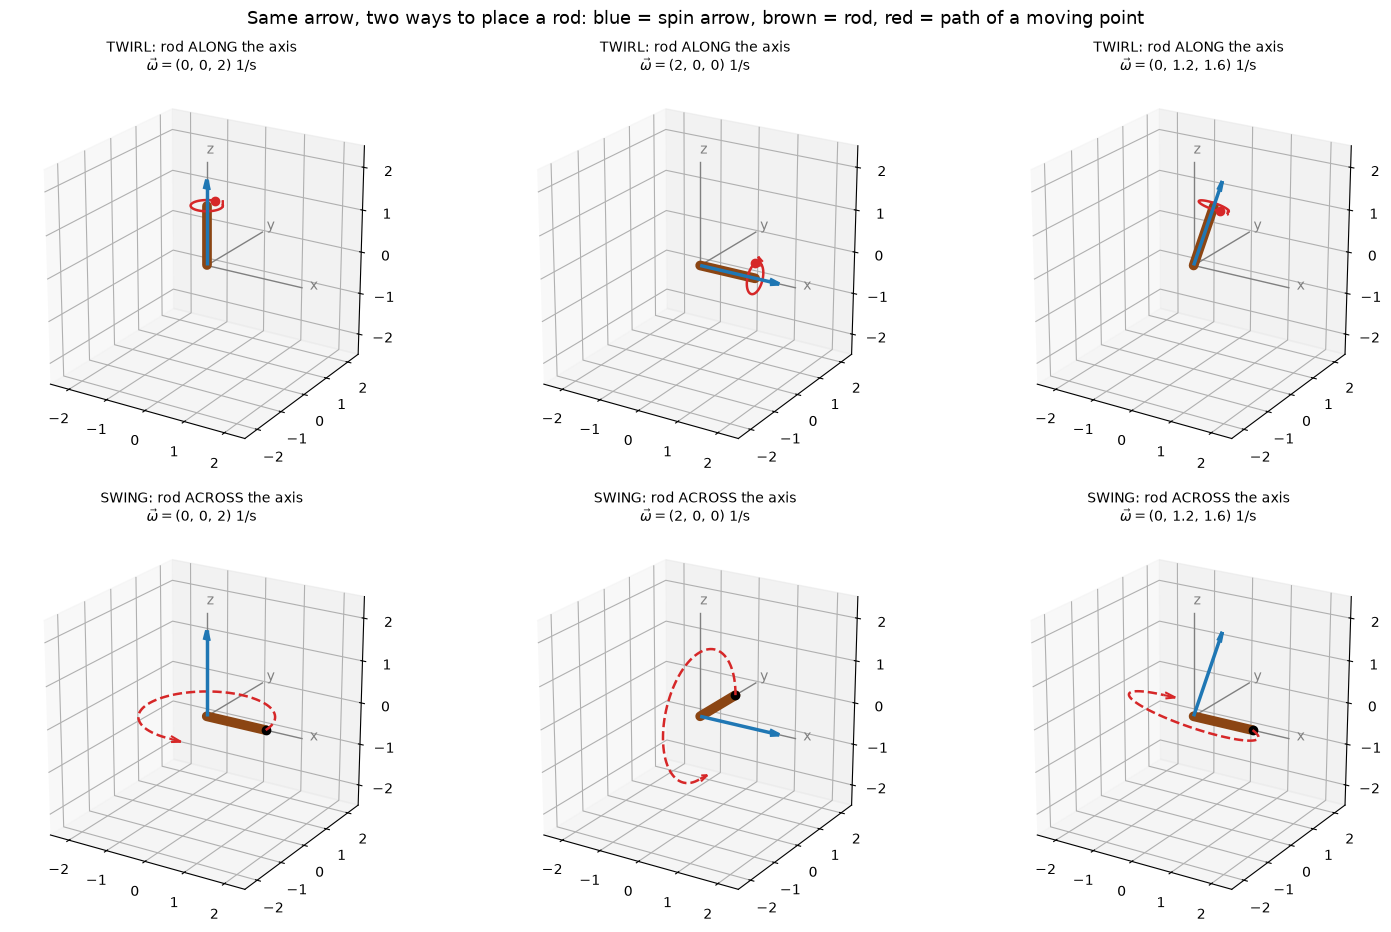

In [2]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# =============================================================================
# STEP 1: three spin arrows, each drawn with a rod in two ways
#   What we have:  omega = (0,0,2), (2,0,0), (0,1.2,1.6) in 1/s
#   What we want:  see TWIRL (rod along the axis) and SWING (rod across the axis)
#   Why:           the arrow omega only records axis, sense, rate. It does not say
#                  where the rod is. The rod's place relative to the axis decides
#                  whether it twirls or swings.
#   Formula:       twirl: rod direction = n        (n = omega / |omega|)
#                  swing: rod direction r_hat with r_hat . n = 0
# =============================================================================
omegas = [np.array([0.0, 0.0, 2.0]), np.array([2.0, 0.0, 0.0]), np.array([0.0, 1.2, 1.6])]
swing_rod_dirs = [np.array([1.0, 0.0, 0.0]), np.array([0.0, 1.0, 0.0]), np.array([1.0, 0.0, 0.0])]

print("STEP 1: checks")
for w, r in zip(omegas, swing_rod_dirs):
    n = w / np.linalg.norm(w)
    print(f"  omega = {w} 1/s   rate = {np.linalg.norm(w):.4f} 1/s   swing rod . n = {np.dot(r, n):.1e} (0 means across the axis)")


# =============================================================================
# STEP 2: helper that draws a circle going round the axis n
#   What we have:  axis n, a starting direction u perpendicular to n, centre, radius
#   What we want:  a curve going counterclockwise seen from the tip of n
#   Why:           right-hand rule: thumb along n, fingers curl along the curve
#   Formula:       v = n x u, so u x v = n;  point(t) = centre + radius (cos t u + sin t v)
# =============================================================================
def circle_about_axis(ax, centre, n, u, radius, color, sweep=1.5 * np.pi, lw=1.8, ls="-", head=True):
    v = np.cross(n, u)
    t = np.linspace(0.0, sweep, 70)
    pts = centre[:, None] + radius * (np.cos(t)[None, :] * u[:, None] + np.sin(t)[None, :] * v[:, None])
    ax.plot(pts[0], pts[1], pts[2], color=color, lw=lw, ls=ls)
    if head:
        tip = pts[:, -1]
        d = pts[:, -1] - pts[:, -3]
        ax.quiver(tip[0], tip[1], tip[2], d[0], d[1], d[2], length=0.3, normalize=True,
                  color=color, arrow_length_ratio=0.9)
    return pts


def draw_frame(ax):
    for vec, label in [((2.4, 0, 0), "x"), ((0, 2.4, 0), "y"), ((0, 0, 2.4), "z")]:
        ax.plot([0, vec[0]], [0, vec[1]], [0, vec[2]], color="gray", lw=1)
        ax.text(vec[0] * 1.08, vec[1] * 1.08, vec[2] * 1.08, label, color="gray")
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_zlim(-2.5, 2.5)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=-58)


# =============================================================================
# STEP 3: top row = TWIRL, rod lies ALONG the axis
#   What we have:  omega and the rod along n (length 1.4 m)
#   What we want:  the rod turning about its own length
#   Why:           points of the rod lie on the axis (s = 0) so the rod itself does not
#                  move; only its surface moves. A ring at the rod's end with a dot on it
#                  shows a surface point going round.
#   Formula:       v = s omega, with s = ring radius = 0.35 m
# =============================================================================
fig = plt.figure(figsize=(15, 9.5))
titles = [r"$\vec{\omega}=(0,\,0,\,2)$ 1/s", r"$\vec{\omega}=(2,\,0,\,0)$ 1/s", r"$\vec{\omega}=(0,\,1.2,\,1.6)$ 1/s"]

for i, w in enumerate(omegas):
    n = w / np.linalg.norm(w)
    ax = fig.add_subplot(2, 3, i + 1, projection="3d")
    draw_frame(ax)
    rod_end = 1.4 * n
    ax.plot([0, rod_end[0]], [0, rod_end[1]], [0, rod_end[2]], color="saddlebrown", lw=7, solid_capstyle="round")
    helper = np.array([1.0, 0.0, 0.0]) if abs(n[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    u = np.cross(n, helper)
    u = u / np.linalg.norm(u)
    pts = circle_about_axis(ax, rod_end, n, u, 0.35, "tab:red", sweep=1.7 * np.pi)
    ax.plot([pts[0, 0]], [pts[1, 0]], [pts[2, 0]], "o", color="tab:red", ms=6)
    ax.quiver(0, 0, 0, w[0], w[1], w[2], color="tab:blue", lw=2.5, arrow_length_ratio=0.12)
    ax.set_title("TWIRL: rod ALONG the axis\n" + titles[i], fontsize=10)


# =============================================================================
# STEP 4: bottom row = SWING, rod lies ACROSS the axis
#   What we have:  the same omega and a rod perpendicular to n (length 1.5 m)
#   What we want:  the rod sweeping round a pivot at the origin
#   Why:           the tip is at distance s = 1.5 m from the axis, so it moves at
#                  v = s omega = 1.5 x 2 = 3 m/s on a circle (dashed)
#   Formula:       r_hat . n = 0, circle through the tip, in the plane perpendicular to n
# =============================================================================
for i, (w, r_hat) in enumerate(zip(omegas, swing_rod_dirs)):
    n = w / np.linalg.norm(w)
    ax = fig.add_subplot(2, 3, i + 4, projection="3d")
    draw_frame(ax)
    tip = 1.5 * r_hat
    ax.plot([0, tip[0]], [0, tip[1]], [0, tip[2]], color="saddlebrown", lw=7, solid_capstyle="round")
    ax.plot([tip[0]], [tip[1]], [tip[2]], "o", color="black", ms=6)
    circle_about_axis(ax, np.zeros(3), n, r_hat, 1.5, "tab:red", sweep=1.5 * np.pi, ls="--")
    ax.quiver(0, 0, 0, w[0], w[1], w[2], color="tab:blue", lw=2.5, arrow_length_ratio=0.12)
    ax.set_title("SWING: rod ACROSS the axis\n" + titles[i], fontsize=10)

fig.suptitle("Same arrow, two ways to place a rod: blue = spin arrow, brown = rod, red = path of a moving point", fontsize=13)
fig.tight_layout()

path = os.path.join(RESULT_DIR, f"spin_arrow_twirl_vs_swing_{TIMESTAMP}.png")
fig.savefig(path, dpi=150)
print("saved the figure")
plt.show()

STEP 2: handle velocity at t = 0 (finite difference)
  door:     v = [-0.  2.  0.] m/s   speed = 2.0000 m/s   omega arrow = [0. 0. 2.] 1/s
  trapdoor: v = [ 0. -0.  2.] m/s   speed = 2.0000 m/s   omega arrow = [2. 0. 0.] 1/s
saved the figure


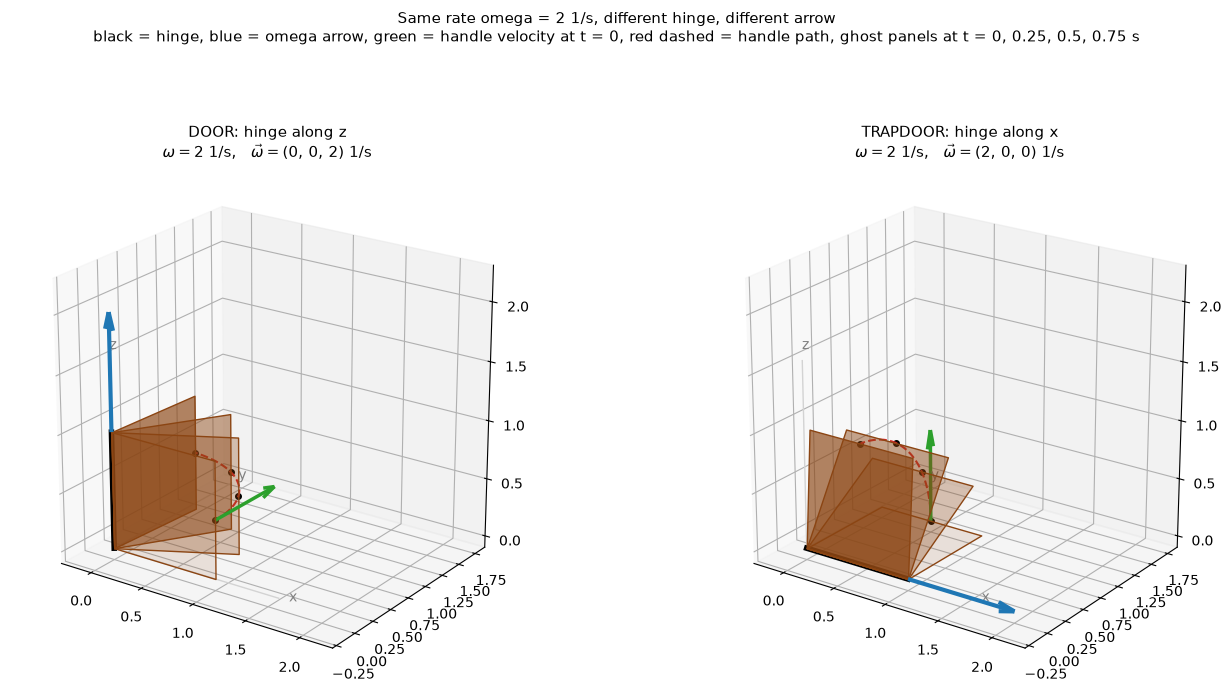

In [3]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from mpl_toolkits.mplot3d.art3d import Poly3DCollection  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# =============================================================================
# STEP 1: the two panels and the same rate
#   What we have:  a door (hinge along z) and a trapdoor (hinge along x), both 1 m x 1 m,
#                  both turning at the same rate omega = 2 1/s, so theta(t) = omega t
#   What we want:  positions of every corner at a few times, as the panel turns
#   Why:           to see that the SAME number omega gives DIFFERENT turnings
#   Formula:       theta(t) = omega t (rad)
#                  door:     rotate about z:  Rz(theta) (x, y, z) = (x c - y s, x s + y c, z)
#                  trapdoor: rotate about x:  Rx(theta) (x, y, z) = (x, y c - z s, y s + z c)
#                  with c = cos(theta), s = sin(theta)
# =============================================================================
OMEGA = 2.0  # 1/s
times = np.array([0.0, 0.25, 0.5, 0.75])  # s
thetas = OMEGA * times  # rad


def Rz(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[c, -s, 0.0], [s, c, 0.0], [0.0, 0.0, 1.0]])


def Rx(theta):
    c, s = np.cos(theta), np.sin(theta)
    return np.array([[1.0, 0.0, 0.0], [0.0, c, -s], [0.0, s, c]])


# door: starts lying along +x, hinge is the z line from z = 0 to z = 1
door_corners = np.array([[0, 0, 0], [1, 0, 0], [1, 0, 1], [0, 0, 1]], dtype=float)
door_handle0 = np.array([1.0, 0.0, 0.5])
# trapdoor: starts lying along +y, hinge is the x line from x = 0 to x = 1
trap_corners = np.array([[0, 0, 0], [1, 0, 0], [1, 1, 0], [0, 1, 0]], dtype=float)
trap_handle0 = np.array([0.5, 1.0, 0.0])

omega_arrow_door = OMEGA * np.array([0.0, 0.0, 1.0])  # omega * z_hat
omega_arrow_trap = OMEGA * np.array([1.0, 0.0, 0.0])  # omega * x_hat

# =============================================================================
# STEP 2: numerical check of handle velocities (finite difference)
#   What we have:  the handle position as a function of time for each panel
#   What we want:  the handle velocity at t = 0
#   Why:           same speed (v = s omega = 1 m x 2 1/s = 2 m/s) but different direction
#   Formula:       v ~ (p(dt) - p(0)) / dt   with dt small
# =============================================================================
dt = 1e-6
v_door = (Rz(OMEGA * dt) @ door_handle0 - door_handle0) / dt
v_trap = (Rx(OMEGA * dt) @ trap_handle0 - trap_handle0) / dt
print("STEP 2: handle velocity at t = 0 (finite difference)")
print(f"  door:     v = {np.round(v_door, 4)} m/s   speed = {np.linalg.norm(v_door):.4f} m/s   omega arrow = {omega_arrow_door} 1/s")
print(f"  trapdoor: v = {np.round(v_trap, 4)} m/s   speed = {np.linalg.norm(v_trap):.4f} m/s   omega arrow = {omega_arrow_trap} 1/s")


# =============================================================================
# STEP 3: draw both panels at four times
#   What we have:  rotation matrices from STEP 1
#   What we want:  ghost panels (fading in with time), the handle path, the hinge,
#                  the omega arrow, and the handle velocity at t = 0
#   Why:           blue omega arrow lies ALONG the hinge; green handle velocity is SIDEWAYS
# =============================================================================
def draw_panel(ax, corners, rot, handle0, omega_arrow, hinge_start, hinge_end, title):
    for vec, label in [((1.6, 0, 0), "x"), ((0, 1.6, 0), "y"), ((0, 0, 1.6), "z")]:
        ax.plot([0, vec[0]], [0, vec[1]], [0, vec[2]], color="lightgray", lw=1)
        ax.text(vec[0] * 1.06, vec[1] * 1.06, vec[2] * 1.06, label, color="gray")
    for k, th in enumerate(thetas):
        pts = (rot(th) @ corners.T).T
        alpha = 0.12 + 0.18 * k
        ax.add_collection3d(Poly3DCollection([pts], facecolor="saddlebrown", edgecolor="saddlebrown", alpha=alpha))
        h = rot(th) @ handle0
        ax.plot([h[0]], [h[1]], [h[2]], "o", color="black", ms=4)
    path_t = np.linspace(0.0, thetas[-1], 60)
    path = np.array([rot(th) @ handle0 for th in path_t])
    ax.plot(path[:, 0], path[:, 1], path[:, 2], "--", color="tab:red", lw=1.5)
    ax.plot([hinge_start[0], hinge_end[0]], [hinge_start[1], hinge_end[1]], [hinge_start[2], hinge_end[2]],
            color="black", lw=4)
    # omega arrow, drawn along the hinge line, starting at the end of the hinge (scale 0.5 per 1/s, drawing only)
    n = omega_arrow / np.linalg.norm(omega_arrow)
    ax.quiver(hinge_end[0], hinge_end[1], hinge_end[2], n[0], n[1], n[2], length=1.0,
              color="tab:blue", lw=3, arrow_length_ratio=0.15)
    # handle velocity at t = 0 (scale 0.4 per m/s, drawing only)
    v = (rot(OMEGA * dt) @ handle0 - handle0) / dt
    vn = v / np.linalg.norm(v)
    ax.quiver(handle0[0], handle0[1], handle0[2], vn[0], vn[1], vn[2], length=0.8,
              color="tab:green", lw=2.5, arrow_length_ratio=0.2)
    ax.set_xlim(-0.3, 2.3)
    ax.set_ylim(-0.3, 1.9)
    ax.set_zlim(-0.1, 2.3)
    ax.set_box_aspect((2.6, 2.2, 2.4))
    ax.view_init(elev=22, azim=-55)
    ax.set_title(title, fontsize=11)


fig = plt.figure(figsize=(14, 7))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
draw_panel(ax1, door_corners, Rz, door_handle0, omega_arrow_door,
           np.array([0.0, 0.0, 0.0]), np.array([0.0, 0.0, 1.0]),
           "DOOR: hinge along z\n" + r"$\omega = 2$ 1/s,   $\vec{\omega} = (0,\,0,\,2)$ 1/s")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
draw_panel(ax2, trap_corners, Rx, trap_handle0, omega_arrow_trap,
           np.array([0.0, 0.0, 0.0]), np.array([1.0, 0.0, 0.0]),
           "TRAPDOOR: hinge along x\n" + r"$\omega = 2$ 1/s,   $\vec{\omega} = (2,\,0,\,0)$ 1/s")

fig.suptitle("Same rate omega = 2 1/s, different hinge, different arrow\n"
             "black = hinge, blue = omega arrow, green = handle velocity at t = 0, red dashed = handle path, "
             "ghost panels at t = 0, 0.25, 0.5, 0.75 s", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.88])

path_png = os.path.join(RESULT_DIR, f"door_vs_trapdoor_{TIMESTAMP}.png")
fig.savefig(path_png, dpi=150)
print("saved the figure")
plt.show()

STEP 1: omega_vec = omega * n_hat
  n_hat given = [1. 0. 0.]   |n_hat given| = 1.00000 (1 up to rounding)
     longitude = 0.00 deg   latitude = 0.00 deg
     omega_vec = [2. 0. 0.] 1/s   length = 2.0000 1/s
  n_hat given = [0.7071 0.7071 0.    ]   |n_hat given| = 0.99999 (1 up to rounding)
     longitude = 45.00 deg   latitude = 0.00 deg
     omega_vec = [1.4142 1.4142 0.    ] 1/s   length = 2.0000 1/s
  n_hat given = [0.5774 0.5774 0.5774]   |n_hat given| = 1.00009 (1 up to rounding)
     longitude = 45.00 deg   latitude = 35.26 deg
     omega_vec = [1.1547 1.1547 1.1547] 1/s   length = 2.0000 1/s
saved the figure


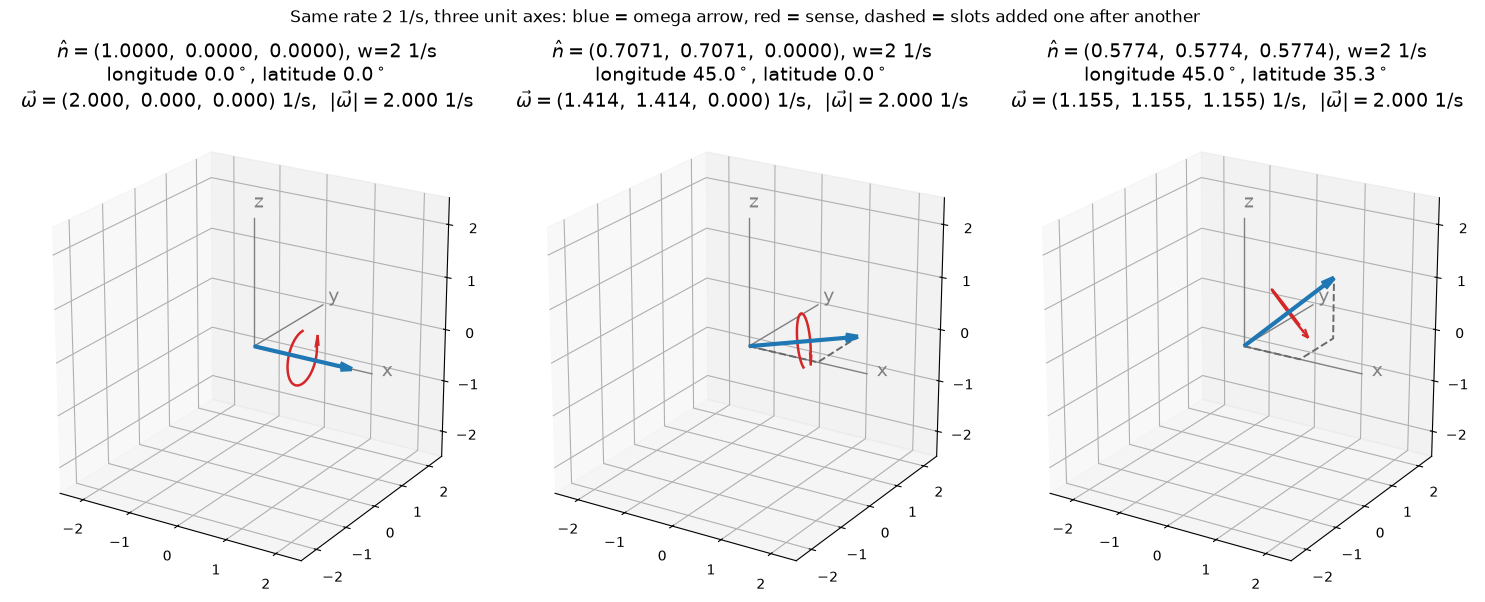

In [11]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# =============================================================================
# STEP 1: from a unit axis arrow and a rate to the omega arrow
#   What we have:  three unit axis arrows n_hat (length 1, given to 4 decimals)
#                  and a rate omega = 2 1/s
#   What we want:  the arrow omega_vec = (omega_x, omega_y, omega_z) in 1/s,
#                  plus where n_hat sits on the unit sphere (longitude, latitude)
#   Why:           the arrow must have LENGTH = rate. n_hat already has length 1, so
#                  we only multiply by the rate. The 4-decimal numbers are rounded, so
#                  dividing by |n_hat| removes the tiny rounding error (about 0.01%).
#   Formulas:      omega_vec = omega * n_hat
#                  check: |omega_vec| = sqrt(omega_x^2 + omega_y^2 + omega_z^2) = omega
#                  longitude = atan2(n_y, n_x),  latitude = arcsin(n_z)
# =============================================================================
RATE = 2.0  # 1/s
unit_axes = [
    np.array([1.0, 0.0, 0.0]),        # on the equator, longitude 0 degrees
    np.array([0.7071, 0.7071, 0.0]),  # on the equator, longitude 45 degrees
    np.array([0.5774, 0.5774, 0.5774]),  # longitude 45 degrees, latitude about 35.3 degrees
]

results = []
print("STEP 1: omega_vec = omega * n_hat")
for d in unit_axes:
    length_before = np.linalg.norm(d)
    n_hat = d / length_before  # removes the rounding error of the 4-decimal numbers
    w_vec = RATE * n_hat
    lon = np.degrees(np.arctan2(n_hat[1], n_hat[0]))
    lat = np.degrees(np.arcsin(n_hat[2]))
    results.append((d, n_hat, w_vec, lon, lat))
    print(f"  n_hat given = {d}   |n_hat given| = {length_before:.5f} (1 up to rounding)")
    print(f"     longitude = {lon:.2f} deg   latitude = {lat:.2f} deg")
    print(f"     omega_vec = {np.round(w_vec, 4)} 1/s   length = {np.linalg.norm(w_vec):.4f} 1/s")


# =============================================================================
# STEP 2: helper that draws the sense of turning around an axis
#   What we have:  unit axis n_hat
#   What we want:  a curve going counterclockwise seen from the tip of n_hat
#   Why:           right-hand rule: thumb along n_hat, fingers curl along the curve
#   Formula:       v = n x u, so u x v = n;  point(t) = centre + r (cos t u + sin t v)
# =============================================================================
def sense_arc(ax, centre, n_hat, radius=0.5, color="tab:red"):
    helper = np.array([1.0, 0.0, 0.0]) if abs(n_hat[0]) < 0.9 else np.array([0.0, 1.0, 0.0])
    u = np.cross(n_hat, helper)
    u = u / np.linalg.norm(u)
    v = np.cross(n_hat, u)
    t = np.linspace(0.0, 1.5 * np.pi, 60)
    pts = centre[:, None] + radius * (np.cos(t)[None, :] * u[:, None] + np.sin(t)[None, :] * v[:, None])
    ax.plot(pts[0], pts[1], pts[2], color=color, lw=1.8)
    tip = pts[:, -1]
    d = pts[:, -1] - pts[:, -3]
    ax.quiver(tip[0], tip[1], tip[2], d[0], d[1], d[2], length=0.25, normalize=True,
              color=color, arrow_length_ratio=0.9)


# =============================================================================
# STEP 3: draw each arrow and its three slots
#   What we have:  the three arrows from STEP 1
#   What we want:  see the arrow and the slots omega_x, omega_y, omega_z that build it
#   Why:           each slot is "how much turning about that axis"; walking along x by
#                  omega_x, then y by omega_y, then z by omega_z arrives at the arrow tip
# =============================================================================
fig = plt.figure(figsize=(15, 6.2))
for i, (d, n_hat, w, lon, lat) in enumerate(results):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    for vec, label in [((2.4, 0, 0), "x"), ((0, 2.4, 0), "y"), ((0, 0, 2.4), "z")]:
        ax.plot([0, vec[0]], [0, vec[1]], [0, vec[2]], color="gray", lw=1)
        ax.text(vec[0] * 1.08, vec[1] * 1.08, vec[2] * 1.08, label, color="gray", fontsize=14)
    # staircase of slots: x part, then y part, then z part
    p0 = np.zeros(3)
    p1 = np.array([w[0], 0.0, 0.0])
    p2 = np.array([w[0], w[1], 0.0])
    p3 = np.array([w[0], w[1], w[2]])
    ax.plot(*zip(p0, p1, p2, p3), color="dimgray", lw=1.4, ls="--")
    ax.quiver(0, 0, 0, w[0], w[1], w[2], color="tab:blue", lw=3, arrow_length_ratio=0.12)
    sense_arc(ax, 0.5 * w, n_hat)
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_zlim(-2.5, 2.5)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=-58)
    ax.set_title(
        rf"$\hat n=({d[0]:.4f},\ {d[1]:.4f},\ {d[2]:.4f})$, w=2 1/s" "\n"
        rf"longitude ${lon:.1f}^\circ$, latitude ${lat:.1f}^\circ$" "\n"
        rf"$\vec{{\omega}}=({w[0]:.3f},\ {w[1]:.3f},\ {w[2]:.3f})$ 1/s,  $|\vec{{\omega}}|={np.linalg.norm(w):.3f}$ 1/s",
        fontsize=14,
    )

fig.suptitle("Same rate 2 1/s, three unit axes: blue = omega arrow, red = sense, dashed = slots added one after another", fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.92])

path = os.path.join(RESULT_DIR, f"spin_arrow_slots_{TIMESTAMP}.png")
fig.savefig(path, dpi=150)
print("saved the figure")
plt.show()